<div align="center">

<h2><strong>PEMBUATAN RECIPE UNTUK GROUNDed SEISMIC PARAMETER RETRIEVAL</strong></h2>
<h3><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h3>

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png"
     alt="Logo Universitas Hasanuddin"
     style="width:220px; margin:20px 0;">

<h5><strong>Oleh:</strong></h5>
<p><strong>SUBHAN APRISA S</strong></p>
<p><strong>H061241041</strong></p>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>2026</strong></p>

</div>

---


 ## **1. STUDI KASUS**
 
 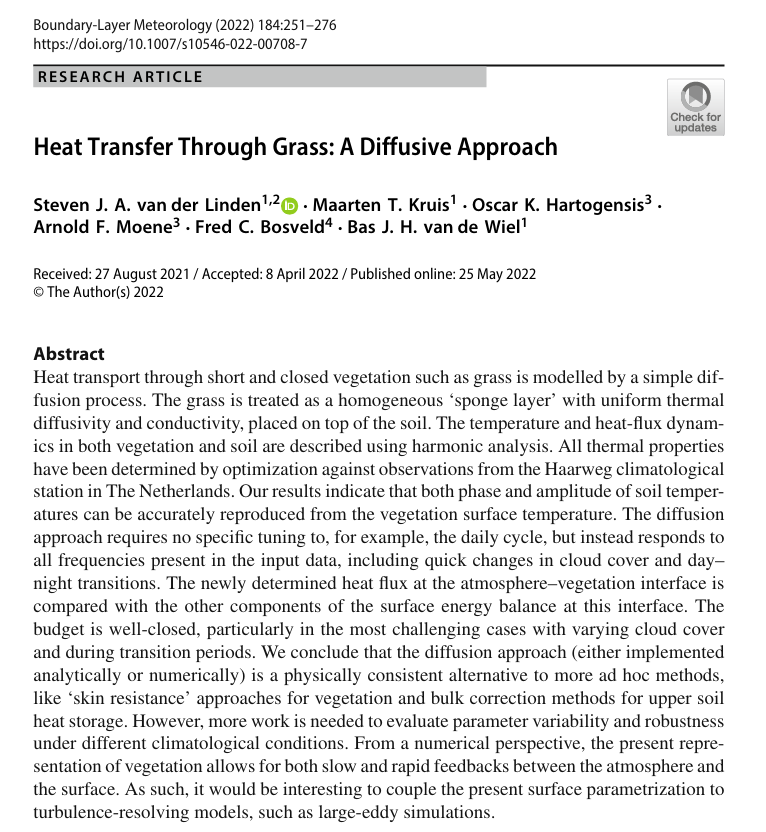
 
Notebook ini mensimulasikan perpindahan panas satu dimensi pada medium berlapis yang terdiri atas lapisan vegetasi dan tanah. Suhu pada permukaan diberi *seasonal forcing* berbentuk sinusoidal, sehingga perubahan suhu berkala dapat merambat ke bawah permukaan. Model digunakan untuk melihat bagaimana amplitudo suhu melemah dan respons suhu mengalami keterlambatan fase seiring bertambahnya kedalaman.

Pendekatan ini merupakan model numerik sederhana untuk pembelajaran. Artikel van der Linden et al. (2022) menjadi acuan konseptual bahwa vegetasi dan tanah dapat diperlakukan sebagai dua lapisan dengan sifat termal berbeda, serta bahwa proses difusi menyebabkan peredaman amplitudo dan pergeseran fase suhu. Implementasi di notebook ini tidak mereplikasi seluruh metode harmonik dan optimasi pada artikel tersebut.


## **2. DASAR TEORI**

Perpindahan panas secara konduksi dapat dijelaskan menggunakan persamaan difusi panas satu dimensi:

$[
\frac{\partial T}{\partial t}=\kappa\frac{\partial^2 T}{\partial z^2}]$

dengan \(T\) adalah suhu (°C), \(t\) waktu (s), \(z\) kedalaman (m), dan \(κ\) difusivitas termal (m²/s). Untuk medium berlapis, setiap lapisan memiliki nilai difusivitas termal masing-masing. Suhu permukaan dimodelkan sebagai:

$[
T(0,t)=T_{mean}+A\sin\left(\frac{2\pi t}{P}\right)
]$

di mana \(T_{mean}\) adalah suhu rata-rata, \(A\) amplitudo perubahan suhu, dan \(P\) periode forcing. Pada contoh ini digunakan periode satu tahun sebagai seasonal forcing. Kondisi batas bawah dibuat tetap agar simulasi stabil dan mudah dibandingkan.



## **3. PERSIAPAN LIBRARY**

Model diselesaikan dengan metode beda hingga eksplisit (*explicit finite difference*). Untuk menjaga kestabilan numerik, rasio difusi \(r=\kappa\Delta t/\Delta z^2\) dijaga tidak lebih dari 0,5 pada setiap lapisan.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Library siap digunakan.")

NumPy: 2.4.4
Library siap digunakan.


## 4. **MENENTUKAN PARAMETER MODEL**

Medium dibagi menjadi lapisan vegetasi tipis di bagian atas dan tanah di bawahnya. Nilai difusivitas dibuat berbeda untuk menggambarkan perbedaan sifat termal kedua lapisan.


In [2]:
# Geometri model
z_max = 2.0             # kedalaman maksimum (m)
dz = 0.01               # interval kedalaman (m)
z = np.arange(0, z_max + dz, dz)
nz = len(z)

# Lapisan: vegetasi 0–0,10 m, kemudian tanah
vegetation_thickness = 0.10
kappa_veg = 8.0e-7      # difusivitas termal vegetasi (m^2/s), ilustratif
kappa_soil = 3.2e-7     # difusivitas termal tanah (m^2/s), ilustratif

kappa = np.where(z <= vegetation_thickness, kappa_veg, kappa_soil)

# Seasonal forcing: satu tahun
seconds_per_day = 24 * 3600
period = 365.0 * seconds_per_day
total_time = 2.0 * period
dt_stability = 0.5 * dz**2 / np.max(kappa)
dt = min(6 * 3600, 0.8 * dt_stability)  # maksimum 6 jam dan tetap stabil
nt = int(total_time / dt) + 1
time = np.arange(nt) * dt
time_days = time / seconds_per_day

T_mean = 18.0           # suhu rata-rata permukaan (°C)
A_surface = 8.0         # amplitudo seasonal (°C)
T_bottom = T_mean       # suhu batas bawah tetap (°C)

r_max = np.max(kappa) * dt / dz**2

print(f"Jumlah node kedalaman : {nz}")
print(f"Langkah waktu         : {dt/3600:.2f} jam")
print(f"Jumlah langkah waktu  : {nt}")
print(f"R maksimum            : {r_max:.3f}")
assert r_max <= 0.5, "Skema eksplisit tidak stabil: kecilkan dt atau perbesar dz." 

Jumlah node kedalaman : 201
Langkah waktu         : 0.01 jam
Jumlah langkah waktu  : 1261440
R maksimum            : 0.400


## **5. MENJALANKAN SIMULASI**

Suhu awal ditetapkan sama dengan suhu rata-rata. Pada setiap langkah waktu, suhu di bagian dalam diperbarui menggunakan persamaan beda hingga. Suhu permukaan mengikuti forcing sinusoidal, sedangkan suhu di batas bawah dijaga tetap.


In [3]:
T = np.full(nz, T_mean, dtype=float)
# Simpan profil pada waktu tertentu untuk dianalisis
save_days = [0, 90, 180, 270, 365, 455, 545, 635, 730]
saved_profiles = {0: T.copy()}
target_steps = {int(round(day * seconds_per_day / dt)): day for day in save_days}

for n in range(1, nt):
    t_now = time[n]
    T_new = T.copy()

    # Kondisi batas atas: perubahan suhu musiman
    T_new[0] = T_mean + A_surface * np.sin(2 * np.pi * t_now / period)

    # Difusi panas di bagian interior; koefisien lokal untuk tiap node
    r = kappa[1:-1] * dt / dz**2
    T_new[1:-1] = T[1:-1] + r * (T[2:] - 2*T[1:-1] + T[:-2])

    # Kondisi batas bawah tetap
    T_new[-1] = T_bottom
    T = T_new

    if n in target_steps:
        saved_profiles[target_steps[n]] = T.copy()

# Rekam suhu sepanjang waktu pada beberapa kedalaman
depths_to_track = [0.0, 0.05, 0.10, 0.25, 0.50, 1.00]
indices = [int(round(d / dz)) for d in depths_to_track]
temperature_series = np.empty((nt, len(indices)))
T = np.full(nz, T_mean, dtype=float)
temperature_series[0, :] = T[indices]

for n in range(1, nt):
    t_now = time[n]
    T_new = T.copy()
    T_new[0] = T_mean + A_surface * np.sin(2 * np.pi * t_now / period)
    r = kappa[1:-1] * dt / dz**2
    T_new[1:-1] = T[1:-1] + r * (T[2:] - 2*T[1:-1] + T[:-2])
    T_new[-1] = T_bottom
    T = T_new
    temperature_series[n, :] = T[indices]

print("Simulasi selesai.")

Simulasi selesai.


## 6. Visualisasi Hasil

Grafik pertama menunjukkan perubahan suhu terhadap waktu pada beberapa kedalaman. Grafik kedua membandingkan profil suhu pada waktu tertentu. Amplitudo yang lebih kecil di kedalaman menunjukkan peredaman sinyal suhu oleh proses difusi.


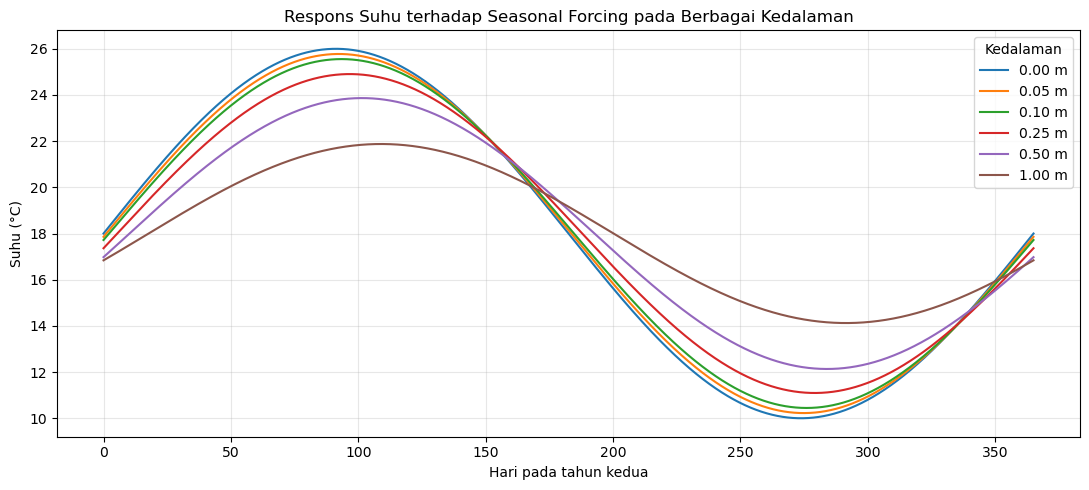

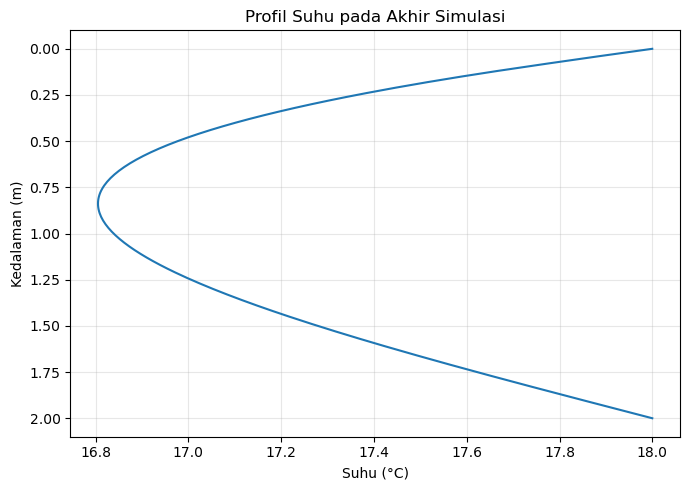

In [4]:
# Deret suhu selama tahun kedua agar efek awal berkurang
mask_year2 = time_days >= 365

plt.figure(figsize=(11, 5))
for j, depth in enumerate(depths_to_track):
    plt.plot(time_days[mask_year2] - 365, temperature_series[mask_year2, j],
             label=f"{depth:.2f} m")
plt.xlabel("Hari pada tahun kedua")
plt.ylabel("Suhu (°C)")
plt.title("Respons Suhu terhadap Seasonal Forcing pada Berbagai Kedalaman")
plt.legend(title="Kedalaman")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Profil suhu di akhir simulasi
plt.figure(figsize=(7, 5))
plt.plot(T, z)
plt.gca().invert_yaxis()
plt.xlabel("Suhu (°C)")
plt.ylabel("Kedalaman (m)")
plt.title("Profil Suhu pada Akhir Simulasi")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. **ANALISIS HASIL**

Secara umum, perubahan suhu musiman paling besar terjadi di permukaan. Ketika kedalaman bertambah, perubahan suhu cenderung semakin kecil dan responsnya tertunda karena panas membutuhkan waktu untuk berdifusi melalui medium. Perbedaan difusivitas antara vegetasi dan tanah memengaruhi laju rambat dan bentuk respons suhu.

Hasil ini bersifat ilustratif karena parameter termal ditetapkan sebagai nilai contoh dan model menggunakan skema numerik sederhana. Artikel van der Linden et al. (2022) menunjukkan pendekatan dua lapisan vegetasi–tanah yang lebih lengkap, dengan analisis harmonik untuk menangani berbagai frekuensi suhu dan optimasi parameter berdasarkan observasi. Karena itu, hasil notebook ini tidak boleh dianggap sebagai reproduksi numerik hasil artikel tersebut.


## 8. **KESIMPULAN**

Model difusi panas berlapis dapat digunakan untuk mempelajari pengaruh seasonal forcing terhadap distribusi suhu bawah permukaan. Simulasi memperlihatkan bahwa amplitudo variasi suhu melemah dengan kedalaman dan respons suhu mengalami keterlambatan. Perbedaan sifat termal vegetasi dan tanah perlu diperhitungkan agar model lebih representatif. Untuk penerapan lapangan, parameter model perlu dikalibrasi menggunakan data suhu dan sifat termal yang terukur.


## 9. **REFERENSI**

van der Linden, S. J. A., Kruis, M. T., Hartogensis, O. K., Moene, A. F., Bosveld, F. C., & van de Wiel, B. J. H. (2022). **Heat Transfer Through Grass: A Diffusive Approach.** *Boundary-Layer Meteorology, 184*, 251–276. https://doi.org/10.1007/s10546-022-00708-7

